<a href="https://colab.research.google.com/github/santoshpashikanti/Ansible-scripts/blob/main/Copy_of_Build_Your_Adv_Agent_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introduction to LangGraph**



Welcome! In this warm-up you’ll the key concepts of **LangGraph**.  

By the end you can:

| You will be able to… | Why it matters |
| --- | --- |
| Explain the parts of a `StateGraph` | All LangGraph projects share these building blocks |
| Write & connect multiple agents | Real-world apps chain specialised LLM tools |
| Inspect state as it flows | Debugging & observability are key |

---

### 📖 Table of Contents  
1. [Install dependencies](#install)  
2. [Define shared state](#state)  
3. [Create three agents](#agents)  
4. [Build the graph](#graph)  
5. [Run & inspect](#run)  
6. [Next steps](#next)


<a id="install"></a>
## Step 1  — Install Dependencies

We need **LangGraph** for orchestration and **LangChain** for helper classes.  
Run the cell below, then **restart the kernel** so the new packages load cleanly.


In [ ]:
!pip install -q --upgrade langgraph langchain  # ! not bare ‘pip’ for Jupyter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.1/158.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.7/111.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 500.1/500.1 kB 12.9 MB/s eta 0:00:00


## Step 2  — Define the Shared State

The **state** is a single `TypedDict` that every agent can **read** and **update**  
— think of it as a strongly-typed, mutable “whiteboard”.

In [ ]:
from typing import TypedDict

class TravelState(TypedDict, total=False):
    user_input: str          # raw question
    destination: str         # “Bali”, “Manali”, …
    itinerary: str           # multi-day plan
    activities: str          # granular activities

## Step 3  — Create Three Simple Agents

| Agent | Responsibility |
| --- | --- |
| `destination_agent` | Choose a place that matches the user’s intent |
| `itinerary_agent` | Draft a rough, three-day itinerary |
| `activity_agent` | Suggest activities fitting that place |

Each agent is an ordinary Python function that takes `TravelState` ➜ returns an **updated** `TravelState`.


In [ ]:
def destination_agent(state: TravelState) -> TravelState:
  """
  Choose a place that matches the user’s intent.
  INput params:
  """
  print("🔧 destination_agent running…")
  # LLM call -> User input
  q = state.get("user_input", "").lower()
  # LLM string parsing logic to decipher what cities are mentioned in the input
  if "beach" in q:
      dest = "Bali"
  elif "snow" in q or "mountain" in q:
      dest = "Manali"
  elif "city break" in q:
      dest = "Paris"
  else:
      dest = "Kyoto"  # sensible default

  print(f"🌍 Suggested destination: {dest}")
  return {**state, "destination": dest}

In [ ]:
def itinerary_agent(state: TravelState) -> TravelState:
    print("🔧 itinerary_agent running…")

    dest = state["destination"]

    plan = (
        f"Day 1: Arrive in {dest}\n"
        f"Day 2: Explore iconic spots in {dest}\n"
        f"Day 3: Relax + sample local cuisine"
    )
    print(f"🧳 Draft itinerary:\n{plan}")
    return {**state, "itinerary": plan}

In [ ]:
def activity_agent(state: TravelState) -> TravelState:
    print("🔧 activity_agent running…")
    dest = state["destination"]
    act = (
        "Snorkelling • Beach yoga"
        if dest == "Bali"
        else "Skiing • Mountain trek"

    )
    print(f"🎯 Suggested activities: {act}")
    return {**state, "activities": act}

## Step 4  — Build the LangGraph Workflow

A `StateGraph` wires **nodes** (our agents) with **edges** (execution order).  
Below we:

1. add each agent as a node  
2. set the entry & finish points  
3. connect the nodes in series  
4. compile to an executable graph


In [ ]:
from langgraph.graph import StateGraph

builder = StateGraph(TravelState)

builder.add_node("destination_agent", destination_agent)
builder.add_node("itinerary_agent", itinerary_agent)
builder.add_node("activity_agent", activity_agent)

builder.set_entry_point("destination_agent")
builder.add_edge("destination_agent", "itinerary_agent")
builder.add_edge("itinerary_agent", "activity_agent")
builder.set_finish_point("activity_agent")

travel_graph = builder.compile()
print("✅ Graph compiled.")

✅ Graph compiled.


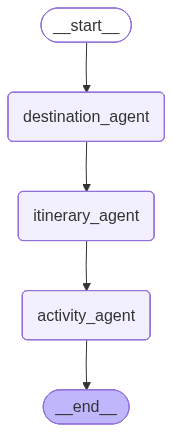

In [ ]:
from IPython.display import Image, display

display(Image(travel_graph.get_graph().draw_mermaid_png()))

## Step 5  — Run & Inspect

Let’s invoke the graph with a sample query and watch the logged output.

In [ ]:
initial_state: TravelState = {
    "user_input": "I want city break"
}

final_state = travel_graph.invoke(initial_state)

print("\n🏁 Final state:")
for k, v in final_state.items():
    print(f"{k}: {v}")

🔧 destination_agent running…
🌍 Suggested destination: Paris
🔧 itinerary_agent running…
🧳 Draft itinerary:
Day 1: Arrive in Paris
Day 2: Explore iconic spots in Paris
Day 3: Relax + sample local cuisine
🔧 activity_agent running…
🎯 Suggested activities: Skiing • Mountain trek

🏁 Final state:
user_input: I want city break
destination: Paris
itinerary: Day 1: Arrive in Paris
Day 2: Explore iconic spots in Paris
Day 3: Relax + sample local cuisine
activities: Skiing • Mountain trek


## 🔬 Understanding State Transitions

Below is a condensed view of how the state mutated:

| After node | `destination` | `itinerary` | `activities` |
| --- | --- | --- | --- |
| **initial** | — | — | — |
| `destination_agent` | ✅ | — | — |
| `itinerary_agent` | ✅ | ✅ | — |
| `activity_agent` | ✅ | ✅ | ✅ |

Each agent **adds** to (or updates) the same `TravelState` object — no hidden globals.


## ✏️ Your Turn  — Get Your Hands Dirty

1. **Snow scenario** — Change the input to “I want a snowy mountain retreat” and re-run.  
   *What destination, itinerary, and activities do you get?*

2. **Branching logic** — Extend `destination_agent` to detect “city break” and route to **Paris**, then tweak `itinerary_agent` accordingly.

*(Feel free to add extra cells beneath this one.)*


In [ ]:
# initial_state_snow: TravelState = {
#     "user_input": "I want a snowy mountain retreat"
# }

# final_state_snow = travel_graph.invoke(initial_state_snow)

# print("\n🏁 Final state for snow scenario:")
# for k, v in final_state_snow.items():
#     print(f"{k}: {v}")

initial_state_city: TravelState = {
    "user_input": "I want a city break"
}

final_state_city = travel_graph.invoke(initial_state_city)

print("\n🏁 Final state for city break scenario:")
for k, v in final_state_city.items():
    print(f"{k}: {v}")

🔧 destination_agent running…
🌍 Suggested destination: Paris
🔧 itinerary_agent running…
🧳 Draft itinerary:
Day 1: Arrive in Paris
Day 2: Explore iconic spots in Paris
Day 3: Relax + sample local cuisine
🔧 activity_agent running…
🎯 Suggested activities: Skiing • Mountain trek

🏁 Final state for city break scenario:
user_input: I want a city break
destination: Paris
itinerary: Day 1: Arrive in Paris
Day 2: Explore iconic spots in Paris
Day 3: Relax + sample local cuisine
activities: Skiing • Mountain trek


# **Build a Multi-Agent System**





## Our Learning Path


| Step | Focus Area             | Description                                     |
|------|------------------------|-------------------------------------------------|
| 1️⃣   | Simple Agent           | Start by creating a basic LLM-powered agent     |
| 2️⃣   |  Multi-Agent System   |  Combine multiple agents using LangGraph    |
| 3️⃣   |  + Short-Term Memory   | Enhance the agent with session-level memory       |





## Step 1 — Setup & Imports


Before we dive into building agents, let's set up our development environment. We'll be using:

- **Google Gemini**: Our powerful LLM for natural language understanding
- **LangGraph**: Framework for building stateful, multi-agent workflows
- **LangChain**: Tools for LLM application development

### Why These Tools?

- **Gemini**: Fast, cost-effective, and excellent for conversational AI
- **LangGraph**: Perfect for complex workflows with multiple agents
- **Environment Variables**: Secure way to handle API keys


In [ ]:
# Install packages (run in terminal or uncomment)
!pip install -q google-generativeai==0.8.5 google-ai-generativelanguage==0.6.15
!pip install -q langchain-google-genai langgraph python-dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.4/155.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 3.1 MB/s eta 0:00:00


In [ ]:
!pip install -q langchain

#### **Set Up API Key for Google AI Studio**

Follow these steps to create and configure your API key for using Google’s AI services (like Gemini):

---

##### 1. Visit the API Key Page

Open the following link in your browser:

👉 [https://aistudio.google.com/apikey](https://aistudio.google.com/apikey)

---

##### 2. Create an API Key

- Sign in with your Google account (if prompted).
- Click on **"Create API Key"**.
- Your API key will be generated — **copy it and keep it secure**.

---

##### 3. Paste Your API Key in the Cell Below

In [ ]:
from dotenv import load_dotenv
import os, getpass

# Load API key
load_dotenv()
os.environ["GOOGLE_API_KEY"] = getpass.getpass("google_apikey")

google_apikey··········


In [ ]:
# Import everything we need
import google.generativeai as genai
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langgraph.graph import StateGraph, END

## Step 2 — Core LLM Chain

We’ll now set up the core LLM using the `ChatGoogleGenerativeAI` class from LangChain (or your preferred wrapper). This model will power our generative AI tasks.




In [ ]:
llm = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash",
    temperature=0.2
)

In [ ]:
llm.invoke("what is the weather in Paris right now")

ChatGoogleGenerativeAIError: Error calling model 'gemini-2.0-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\nPlease retry in 9.566305062s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url'

## Step 3 - Create Individual Agents

### Itenary Agent

Helps in planning the full travel itinerary and provides travel-related answers

In [ ]:
# Install required libraries for Tavily
!pip install -q tavily-python langchain-community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.7/64.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 3.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.5 which is incompatible.


In [ ]:
# Import necessary modules
from langchain_core.tools import tool
from langchain_core.messages import ToolMessage
from typing import TypedDict, Annotated, List, Union
import json

###### Set Up Tavily API Key

Tavily provides real-time web search capabilities for LLMs. To use it, you'll need an API key.

---

##### Get Your Tavily API Key

1. Visit the Tavily dashboard:  
   👉 [https://app.tavily.com/home](https://app.tavily.com/home)
2. Sign in or create an account.
3. Go to the **API Keys** section.
4. Copy your API key.

---

##### Enter Your API Key Securely in Colab

In [ ]:
# Step 1: Set up Tavily client and API key

os.environ["TAVILY_API_KEY"] = getpass.getpass("TAVILY_API_KEY")
#tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

TAVILY_API_KEY··········


In [ ]:
# Install or upgrade the LangChain-Tavily integration package silently
!pip install -q -U langchain-tavily

###### Use TavilySearch Tool from LangChain

Now that we’ve set up the Tavily API key, we can use the `TavilySearch` tool to perform real-time web searches within LangChain.

In [ ]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tools = [tool]

In [ ]:
# Test TavilySearch
tool.invoke("What is the weather in Paris right now?")

{'query': 'What is the weather in Paris right now?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'title': 'Weather in Paris',
   'url': 'https://www.weatherapi.com/',
   'content': "{'location': {'name': 'Paris', 'region': 'Ile-de-France', 'country': 'France', 'lat': 48.8667, 'lon': 2.3333, 'tz_id': 'Europe/Paris', 'localtime_epoch': 1770862354, 'localtime': '2026-02-12 03:12'}, 'current': {'last_updated_epoch': 1770865200, 'last_updated': '2026-02-12 04:00', 'temp_c': 11.1, 'temp_f': 52.0, 'is_day': 0, 'condition': {'text': 'Light rain', 'icon': '//cdn.weatherapi.com/weather/64x64/night/296.png', 'code': 1183}, 'wind_mph': 16.6, 'wind_kph': 26.6, 'wind_degree': 231, 'wind_dir': 'SW', 'pressure_mb': 975.0, 'pressure_in': 28.79, 'precip_mm': 1.09, 'precip_in': 0.04, 'humidity': 87, 'cloud': 100, 'feelslike_c': 8.2, 'feelslike_f': 46.8, 'windchill_c': 7.5, 'windchill_f': 45.6, 'heatindex_c': 10.6, 'heatindex_f': 51.0, 'dewpoint_c': 7.8, 'dewpoint_f': 46.1,

In [ ]:
# itinerary agent prompt to include ReAct reasoning
itenary_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are an expert travel itinerary planner. ONLY respond to travel planning and itinerary-related questions.

IMPORTANT RULES:
- If asked about non-travel topics (weather, math, general questions), politely decline and redirect to travel planning
- Always provide complete, well-formatted itineraries with specific details
- Include timing, locations, transportation, and practical tips

Use the ReAct approach:
1. THOUGHT: Analyze what travel information is needed
2. ACTION: Search for current information about destinations, attractions, prices, hours
3. OBSERVATION: Process the search results
4. Provide a comprehensive, formatted response

Available tools:
- TavilySearch: Search for current travel information

Format your itineraries with:
- Clear day-by-day breakdown
- Specific times and locations
- Transportation between locations
- Estimated costs when possible
- Practical tips and recommendations"""),
    MessagesPlaceholder(variable_name="messages"),
])

In [ ]:
# Bind tools to the LLM
llm_with_tools = llm.bind_tools(tools)

In [ ]:
# Create itinerary agent
itenary_agent = itenary_prompt | llm_with_tools
# llm_with_tools.invoke(itenary_prompt)


### Flight Search Agent

Searches for hotels based on user queries (location, date, budget)

In [ ]:
# Install required packages for flight agent
!pip install -q serpapi

###### Set Up SERP API Key (Google Search API)

SERP API allows you to access Google Search results in real time — useful for web search, SEO tools, and AI assistants.

---

##### Get Your SERP API Key

1. Visit the SERP API dashboard:  
   👉 [https://serpapi.com/dashboard](https://serpapi.com/dashboard)
2. Sign up or log in.
3. Copy your **private API key** from the dashboard.

---

##### Enter Your API Key Securely in Colab



In [ ]:
import serpapi

# Set up SERP API key
os.environ["SERPAPI_API_KEY"] = getpass.getpass("SERPAPI_API_KEY")

SERPAPI_API_KEY··········


###### Build Flight Search Tool

In [ ]:
from langchain_core.tools import Tool

# # Build flight search tool
# def search_flights(departure_airport: str, arrival_airport: str, outbound_date: str, return_date: str = None, adults: int = 1, children: int = 0) -> str:
#     """
#     Search for flights using Google Flights engine.

#     Args:
#         departure_airport: Departure airport code (e.g., 'NYC', 'LAX')
#         arrival_airport: Arrival airport code (e.g., 'LON', 'NRT')
#         outbound_date: Departure date (YYYY-MM-DD format)
#         return_date: Return date (YYYY-MM-DD format, optional for one-way)
#         adults: Number of adult passengers (default: 1)
#         children: Number of child passengers (default: 0)
#     """
#     params = {
#         'api_key': os.environ.get('SERPAPI_API_KEY'),
#         'engine': 'google_flights',
#         'hl': 'en',
#         'gl': 'us',
#         'departure_id': departure_airport,
#         'arrival_id': arrival_airport,
#         'outbound_date': outbound_date,
#         'return_date': return_date,
#         'currency': 'USD',
#         'adults': adults,
#         'children': children,
#         'stops': '0,1,2+'
#     }

#     try:
#         search = serpapi.search(params)
#         results = search.data.get('best_flights', [])

#         if not results:
#             # Print the full search data if no flights are found
#             print("SERP API returned no flights. Full data:")
#             print(json.dumps(search.data, indent=2))
#             return "No flights found for the given criteria."

#         return json.dumps(results, indent=2)
#     except Exception as e:
#         return f"Flight search failed: {str(e)}"

In [ ]:
# # # Define the tool explicitly
# search_flights_tool = Tool.from_function(
#     func=search_flights,
#     name="search_flights",
#     description="Search for flights using Google Flights engine."
# )

In [ ]:
!pip uninstall -y serpapi
!pip install -U google-search-results

Found existing installation: serpapi 0.1.5
Uninstalling serpapi-0.1.5:
  Successfully uninstalled serpapi-0.1.5
  Preparing metadata (setup.py) ... done
  Created wheel for google-search-results: filename=google_search_results-2.4.2-py3-none-any.whl size=32010 sha256=999446200bbb2b50a3356dba6e6d1191913a727538a79366a250c489faf91aa2
  Stored in directory: /root/.cache/pip/wheels/0c/47/f5/89b7e770ab2996baf8c910e7353d6391e373075a0ac213519e
Successfully built google-search-results


In [ ]:
from serpapi.google_search import GoogleSearch

print("✅ GoogleSearch available!")


✅ GoogleSearch available!


In [ ]:
from serpapi.google_search import GoogleSearch
import json, os

def search_flights(departure_airport: str, arrival_airport: str,
                   outbound_date: str, return_date: str = None,
                   adults: int = 1, children: int = 0) -> str:
    """Search and format flight results nicely."""
    params = {
        "api_key": os.environ.get("SERPAPI_API_KEY"),
        "engine": "google_flights",
        "departure_id": departure_airport,
        "arrival_id": arrival_airport,
        "outbound_date": outbound_date,
        "return_date": return_date,
        "currency": "USD",
        "adults": adults,
        "children": children,
    }

    try:
        search = GoogleSearch(params)
        results = search.get_dict()
        flights = results.get("best_flights") or results.get("other_flights", [])
        if not flights:
            return f"No flights found for the given criteria. Here are the results from the search engine: {results}"

        formatted = []
        for f in flights[:15]:
            main = f["flights"][0]
            airline = main.get("airline", "Unknown")
            dep = main["departure_airport"]["name"]
            arr = main["arrival_airport"]["name"]
            dep_time = main["departure_airport"]["time"]
            arr_time = main["arrival_airport"]["time"]
            duration = f.get("total_duration", main.get("duration"))
            price = f.get("price", "N/A")
            cls = main.get("travel_class", "Unknown")

            formatted.append(
                f"- {airline} ({cls}) — ${price}, {duration} min\n"
                f"  {dep} ({dep_time}) → {arr} ({arr_time})"
            )

        return "✈️ **Top Flight Options:**\n" + "\n\n".join(formatted)

    except Exception as e:
        return f"Flight search failed: {str(e)}"


In [ ]:
# Test the search_flights tool directly
departure = "JFK" # Assuming Boston (BOS) as airport code for Boston
arrival = "SFO" # Assuming Paris Charles de Gaulle (CDG) as airport code for Paris
outbound = "2026-03-29"
return_date = "2026-04-06"
adults = 1

raw_flight_results = search_flights(
    departure_airport=departure,
    arrival_airport=arrival,
    outbound_date=outbound,
    return_date=return_date,
    adults=adults
)

print("Raw results from search_flights tool:")
print(raw_flight_results)

Raw results from search_flights tool:
✈️ **Top Flight Options:**
- American (Economy) — $501, 403 min
  John F. Kennedy International Airport (2026-03-29 08:05) → San Francisco International Airport (2026-03-29 11:48)

- JetBlue (Economy) — $548, 410 min
  John F. Kennedy International Airport (2026-03-29 20:30) → San Francisco International Airport (2026-03-30 00:20)

- Delta (Economy) — $717, 394 min
  John F. Kennedy International Airport (2026-03-29 15:20) → San Francisco International Airport (2026-03-29 18:54)


In [ ]:
from langchain_core.tools import Tool

search_flights_tool = Tool.from_function(
    func=search_flights,
    name="search_flights",
    description="Search for flights using Google Flights via SerpApi."
)


In [ ]:
from pydantic import BaseModel
from typing import Optional

class FlightSearchParams(BaseModel):
    departure_airport: str
    arrival_airport: str
    outbound_date: str
    return_date: Optional[str] = None
    adults: int = 1
    children: int = 0


from langchain_core.output_parsers import PydanticOutputParser

parser = PydanticOutputParser(pydantic_object=FlightSearchParams)

flight_extraction_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a flight booking assistant. Extract structured flight parameters from the user's message.
Return them as a JSON object matching this format:
{{
  "departure_airport": "...",
  "arrival_airport": "...",
  "outbound_date": "...",
  "return_date": "...",
  "adults": ...,
  "children": ...
}}
"""),
    ("human", "{user_query}")
])

flight_extraction_chain = flight_extraction_prompt | llm | parser



In [ ]:
AIRPORT_CODE_MAP = {
    "boston": "BOS",
    "san francisco": "SFO",
    "new york": "JFK",
    "nyc": "JFK",
    "newark": "EWR",
    "los angeles": "LAX",
    "chicago": "ORD",
    "seattle": "SEA",
    "paris": "CDG",
    "london": "LHR",
    "delhi": "DEL",
    "tokyo": "NRT",
    "singapore": "SIN",
    "munich": "MUC",
    "nagpur": "NAG"
}
def normalize_airport_code(name: str) -> str:
    """Convert airport city names to IATA codes if possible."""
    if not name:
        return name
    name_lower = name.strip().lower()
    return AIRPORT_CODE_MAP.get(name_lower, name.upper())  # fallback: uppercase



from dateutil import parser as date_parser
from datetime import datetime

def normalize_date(date_str: str) -> str:
    """Convert various human date formats (e.g., 'Nov 29 2025') to 'YYYY-MM-DD'."""
    if not date_str:
        return date_str
    try:
        parsed = date_parser.parse(date_str)
        return parsed.strftime("%Y-%m-%d")
    except Exception:
        # fallback: return unchanged
        return date_str



In [ ]:
def run_flight_agent(user_query: str):
    print(f"🧠 Extracting parameters for: '{user_query}'")
    params: FlightSearchParams = flight_extraction_chain.invoke({"user_query": user_query})
    print("✅ Extracted parameters:")
    print(params.model_dump_json(indent=2))

    # Normalize airport codes
    params.departure_airport = normalize_airport_code(params.departure_airport)
    params.arrival_airport = normalize_airport_code(params.arrival_airport)

    # Normalize date formats
    params.outbound_date = normalize_date(params.outbound_date)
    params.return_date = normalize_date(params.return_date)

    print("\n✈️ Normalized Parameters:")
    print(f"  Departure: {params.departure_airport}")
    print(f"  Arrival:   {params.arrival_airport}")
    print(f"  Outbound:  {params.outbound_date}")
    print(f"  Return:    {params.return_date}")

    print("\n🌍 Searching flights...")
    result = search_flights(
        departure_airport=params.departure_airport,
        arrival_airport=params.arrival_airport,
        outbound_date=params.outbound_date,
        return_date=params.return_date,
        adults=params.adults,
        children=params.children
    )

    return result


In [ ]:
# user_query = "Book a flight from Munich to nyc for 2 adults leaving on January 15 2026 and returning on January 26 2026"

# result = run_flight_agent(user_query)
# print("\n--- Final Flight Results ---\n")
# print(result)


##### Define Flight Agent

In [ ]:
# flight agent prompt
flight_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a flight booking expert. ONLY respond to flight-related queries.

IMPORTANT RULES:
- If asked about non-flight topics, politely decline and redirect to flight booking
- Always use the search_flights tool to find current flight information
- You CAN search for flights and analyze the results for:
  * Direct flights vs connecting flights
  * Different airlines and flight classes
  * Various price ranges and timing options
  * Flight duration and layover information
- When users ask for specific preferences (direct flights, specific class, etc.), search first then filter/analyze the results
- Present results clearly organized by outbound and return flights

Available tools:
- search_flights: Search for comprehensive flight data that includes all airlines, classes, and connection types

Process:
1. ALWAYS search for flights first using the tool
2. Analyze the results to find flights matching user preferences
3. Present organized results with clear recommendations

Airport code mapping:
- Delhi: DEL
- London Heathrow: LHR
- New York: JFK/LGA/EWR
- etc."""),
    MessagesPlaceholder(variable_name="messages"),
])


In [ ]:
# Bind tools and create flight agent
llm_with_flight_tools = llm.bind_tools([search_flights_tool])

In [ ]:
flight_agent = flight_prompt | llm_with_flight_tools

### Hotel Agent

In [ ]:
# hotel search tool
def search_hotels(location: str, check_in_date: str, check_out_date: str, adults: int = 1, children: int = 0, rooms: int = 1, hotel_class: str = None, sort_by: int = 8) -> str:
    """
    Search for hotels using Google Hotels engine.

    Args:
        location: Location to search for hotels (e.g., 'New York', 'Paris', 'Tokyo')
        check_in_date: Check-in date (YYYY-MM-DD format)
        check_out_date: Check-out date (YYYY-MM-DD format)
        adults: Number of adults (default: 1)
        children: Number of children (default: 0)
        rooms: Number of rooms (default: 1)
        hotel_class: Hotel class filter (e.g., '2,3,4' for 2-4 star hotels)
        sort_by: Sort parameter (default: 8 for highest rating)
    """

    # Ensure proper integer types
    adults = int(float(adults)) if adults else 1
    children = int(float(children)) if children else 0
    rooms = int(float(rooms)) if rooms else 1
    sort_by = int(float(sort_by)) if sort_by else 8

    params = {
        'api_key': os.environ.get('SERPAPI_API_KEY'),
        'engine': 'google_hotels',
        'hl': 'en',
        'gl': 'us',
        'q': location,
        'check_in_date': check_in_date,
        'check_out_date': check_out_date,
        'currency': 'USD',
        'adults': adults,
        'children': children,
        'rooms': rooms,
        'sort_by': sort_by
    }

    # Only add hotel_class if provided
    if hotel_class:
        params['hotel_class'] = hotel_class

    try:
        search = serpapi.search(params)
        properties = search.data.get('properties', [])

        if not properties:
            return f"No hotels found. Available data keys: {list(search.data.keys())}"

        # Return top 5 results
        return json.dumps(properties[:5], indent=2)

    except Exception as e:
        return f"Hotel search failed: {str(e)}"

In [ ]:
# Hotel agent prompt
hotel_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a hotel booking expert. ONLY respond to hotel and accommodation-related queries.

IMPORTANT RULES:
- If asked about non-hotel topics, politely decline and redirect to hotel booking
- Always use the search_hotels tool to find current hotel information
- Provide detailed hotel options with prices, ratings, amenities, and location details
- Include practical booking advice and tips
- You CAN search and analyze results for different criteria like star ratings, price ranges, amenities

Available tools:
- search_hotels: Search for hotels using Google Hotels engine

When searching hotels, extract or ask for:
- Location/destination
- Check-in and check-out dates (YYYY-MM-DD format)
- Number of guests (adults, children)
- Number of rooms
- Hotel preferences (star rating, amenities, etc.)

Present results with:
- Hotel name and star rating
- Price per night and total cost
- Key amenities and features
- Location and nearby attractions
- Booking recommendations"""),
    MessagesPlaceholder(variable_name="messages"),
])

In [ ]:
# Bind tools and create hotel agent
llm_with_hotel_tools = llm.bind_tools([search_hotels])
hotel_agent = hotel_prompt | llm_with_hotel_tools

## Step 4 - Create Router


In [ ]:
from langchain_core.output_parsers import StrOutputParser

def create_router():
    """Creates a router for the three travel agents using LangGraph patterns"""

    router_prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a routing expert for a travel planning system.

        Analyze the user's query and decide which specialist agent should handle it:

        - FLIGHT: Flight bookings, airlines, air travel, flight search, tickets, airports, departures, arrivals, airline prices
        - HOTEL: Hotels, accommodations, stays, rooms, hotel bookings, lodging, resorts, hotel search, hotel prices
        - ITINERARY: Travel itineraries, trip planning, destinations, activities, attractions, sightseeing, travel advice, weather, culture, food, general travel questions

        Respond with ONLY one word: FLIGHT, HOTEL, or ITINERARY

        Examples:
        "Book me a flight to Paris" → FLIGHT
        "Find hotels in Tokyo" → HOTEL
        "Plan my 5-day trip to Italy" → ITINERARY
        "Search flights from NYC to London" → FLIGHT
        "Where should I stay in Bali?" → HOTEL
        "What are the best attractions in Rome?" → ITINERARY
        "I need airline tickets" → FLIGHT
        "Show me hotel options" → HOTEL
        "Create an itinerary for Japan" → ITINERARY"""),

        ("user", "Query: {query}")
    ])

    router_chain = router_prompt | llm | StrOutputParser()
    def route_query(state):
        """Router function for LangGraph - decides which agent to call next"""

        # Get the latest user message
        user_message = state["messages"][-1].content

        print(f"🧭 Router analyzing: '{user_message[:50]}...'")

        try:
            # Get LLM routing decision
            decision = router_chain.invoke({"query": user_message}).strip().upper()

            # Map to our agent node names
            agent_mapping = {
                "FLIGHT": "flight_agent",
                "HOTEL": "hotel_agent",
                "ITINERARY": "itenary_agent"
            }

            next_agent = agent_mapping.get(decision, "itenary_agent")
            print(f"🎯 Router decision: {decision} → {next_agent}")

            return next_agent

        except Exception as e:
            print(f"⚠️ Router error, defaulting to itenary_agent: {e}")
            return "itenary_agent"

    return route_query

In [ ]:
# Create the router
router = create_router()
print("✅ Travel Router created for LangGraph!")

✅ Travel Router created for LangGraph!


## Step 5 - Define the State Schema

In [ ]:
from typing import TypedDict, Annotated, List, Optional
import operator
from langchain_core.messages import BaseMessage

class TravelPlannerState(TypedDict):
    """Simple state schema for travel multiagent system"""

    # Conversation history - persisted with checkpoint memory
    messages: Annotated[List[BaseMessage], operator.add]

    # Agent routing
    next_agent: Optional[str]

    # Current user query
    user_query: Optional[str]

## Step 6 - Create Agent Nodes

###### Itenary Agent Node

In [ ]:
from langchain_core.messages import ToolMessage

# Agent node functions
def itinerary_agent_node(state: TravelPlannerState):
    """Itinerary planning agent node"""
    messages = state["messages"]
    response = itenary_agent.invoke({"messages": messages})

    # Handle tool calls if present
    if hasattr(response, 'tool_calls') and response.tool_calls:
        tool_messages = []
        for tool_call in response.tool_calls:
            if tool_call['name'] == 'tavily_search_results_json':
                try:
                    tool_result = tool.search(query=tool_call['args']['query'], max_results=2)
                    tool_result = json.dumps(tool_result, indent=2)
                except Exception as e:
                    tool_result = f"Search failed: {str(e)}"

                tool_messages.append(ToolMessage(
                    content=tool_result,
                    tool_call_id=tool_call['id']
                ))

        if tool_messages:
            all_messages = messages + [response] + tool_messages
            final_response = itenary_agent.invoke({"messages": all_messages})
            return {"messages": [response] + tool_messages + [final_response]}

    return {"messages": [response]}

###### Flight Agent Agent Node

In [ ]:
def flight_agent_node(state: TravelPlannerState):
    """Flight booking agent node"""
    messages = state["messages"]
    user_query = messages[-1].content # Get the latest user message

    # Use the run_flight_agent function to handle extraction, normalization, and search
    tool_result = run_flight_agent(user_query)

    # The run_flight_agent function already returns a formatted string or an error message
    # We can wrap this in a ToolMessage to simulate a tool call result being returned to the LLM
    # Or, simply return the result as a HumanMessage for now, as the tool is already executed

    # Option 1: Return as a ToolMessage (more aligned with ReAct, but requires another LLM call to format)
    # tool_messages = [ToolMessage(content=tool_result, tool_call_id="simulated_tool_call_id")]
    # all_messages = messages + tool_messages
    # final_response = flight_agent.invoke({"messages": all_messages}) # This would require the flight_agent to process tool results
    # return {"messages": tool_messages + [final_response]}

    # Option 2: Directly return the formatted result as the final message
    # This bypasses the need for the LLM to process the tool output again
    from langchain_core.messages import HumanMessage
    return {"messages": [HumanMessage(content=tool_result)]}

###### Hotel Agent Node

In [ ]:
def hotel_agent_node(state: TravelPlannerState):
    """Hotel booking agent node"""
    messages = state["messages"]
    response = hotel_agent.invoke({"messages": messages})

    if hasattr(response, 'tool_calls') and response.tool_calls:
        tool_messages = []
        for tool_call in response.tool_calls:
            if tool_call['name'] == 'search_hotels':
                try:
                    tool_result = search_hotels(**tool_call['args'])
                except Exception as e:
                    tool_result = f"Hotel search failed: {str(e)}"

                tool_messages.append(ToolMessage(
                    content=tool_result,
                    tool_call_id=tool_call['id']
                ))

        if tool_messages:
            all_messages = messages + [response] + tool_messages
            final_response = hotel_agent.invoke({"messages": all_messages})
            return {"messages": [response] + tool_messages + [final_response]}

    return {"messages": [response]}

###### Router Node

In [ ]:
def router_node(state: TravelPlannerState):
    """Router node - determines which agent should handle the query"""
    user_message = state["messages"][-1].content
    next_agent = router(state)

    return {
        "next_agent": next_agent,
        "user_query": user_message
    }

## Step 7 - Conditonal Function

In [ ]:
# Conditional routing function

def route_to_agent(state: TravelPlannerState):
    """Conditional edge function - routes to appropriate agent based on router decision"""

    next_agent = state.get("next_agent")

    if next_agent == "flight_agent":
        return "flight_agent"
    elif next_agent == "hotel_agent":
        return "hotel_agent"
    elif next_agent == "itenary_agent":
        return "itenary_agent"
    else:
        # Default fallback
        return "itenary_agent"


##### ----> A better approach
# def route_to_agent(state: TravelPlannerState) -> Literal["flight_agent", "hotel_agent", "itenary_agent"]:
#     """Route to the appropriate agent based on router decision"""
#     return state["next_agent"]

## Step 8 - Build Graph & Add Memory

In [ ]:
from langgraph.graph import StateGraph, END
from typing import Literal
from langgraph.checkpoint.memory import InMemorySaver

# Build the complete travel planning graph
workflow = StateGraph(TravelPlannerState)

# Add all nodes to the graph
workflow.add_node("router", router_node)
workflow.add_node("flight_agent", flight_agent_node)
workflow.add_node("hotel_agent", hotel_agent_node)
workflow.add_node("itenary_agent", itinerary_agent_node)

In [ ]:
# Set entry point - always start with router
workflow.set_entry_point("router")

# Add conditional edge from router to appropriate agent
workflow.add_conditional_edges(
    "router",
    route_to_agent,
    {
        "flight_agent": "flight_agent",
        "hotel_agent": "hotel_agent",
        "itenary_agent": "itenary_agent"
    }
)

# Add edges from each agent back to END
workflow.add_edge("flight_agent", END)
workflow.add_edge("hotel_agent", END)
workflow.add_edge("itenary_agent", END)

checkpointer = InMemorySaver()

# Compile the graph
travel_planner = workflow.compile(checkpointer=checkpointer)

print("✅ Travel Planning Graph built successfully!")

✅ Travel Planning Graph built successfully!


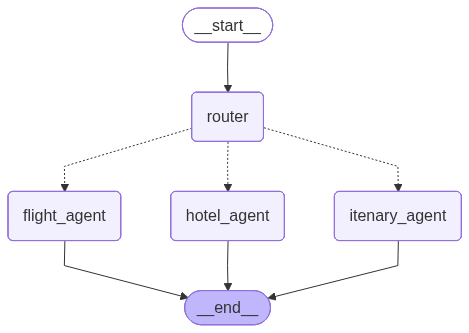

In [ ]:
from IPython.display import Image, display

# Generate and display the graph
graph_image = travel_planner.get_graph().draw_mermaid_png()
display(Image(graph_image))

## Step 9 - Test Your Mullti-Agent System

In [ ]:
from langchain_core.messages import HumanMessage

def test_system(query):
    """Test our multi-agent system"""
    print(f"🧑 User: {query}")

    # Create initial state
    initial_state = {
        "messages": [HumanMessage(content=query)],
        "next_agent": ""
    }

    # For testing purposes, use a fixed thread_id
    config = {"configurable": {"thread_id": "test_thread"}}

    # Run the system (use travel_planner instead of app)
    result = travel_planner.invoke(initial_state, config=config)

    # Get the response
    response = result["messages"][-1].content
    print(f"🤖 Assistant: {response}")
    print("-" * 50)

In [ ]:
# Test with different queries
test_system("I need to book a flight from  BOS to CDG, from Oct 28 to October 31 for year 2026 for 1 person")
# test_system("I need to book a flight from  CDG to BOS, from January 28 to February 5 for year 2026 for 1 person. Print full output")
# test_system("Find me a 4-star hotel in Burlington, Vermont for 2 nights for 2 adults on 28 March 2026")
# test_system("Design a 10 day itinerary for San Francisco trip with famous attractions")
# test_system("Book a flight from Boston to New York on 21 December 2025 returning on January 12 2026 for 1 adult")
# test_system("What is the weather in Paris right now?")
# test_system("find me a motel in Licolin New Hampshire for 1 adult on Feb 21 2026 for 2 days")

🧑 User: I need to book a flight from  BOS to CDG, from Oct 28 to October 31 for year 2026 for 1 person
🧭 Router analyzing: 'I need to book a flight from  BOS to CDG, from Oct...'
⚠️ Router error, defaulting to itenary_agent: Error calling model 'gemini-2.0-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash

ChatGoogleGenerativeAIError: Error calling model 'gemini-2.0-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-2.0-flash\nPlease retry in 53.530553649s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url

## Step 10 - Build an Interactive Chatbot

In [ ]:
# ZAdftgyuhj
from langchain_core.messages import HumanMessage

def multi_turn_chat():
    """Multi-turn conversation with checkpoint memory"""
    print("💬 Multi-Agent Travel Assistant (Multi-turn Mode)")
    print("=" * 50)

    # For multi-turn, you need a consistent thread/session ID
    config = {"configurable": {"thread_id": "1"}}

    while True:
        user_input = input("\n🧑 You: ")

        if user_input.lower() == 'quit':
            break

        print(f"\n📊 Processing query...")

        # For multi-turn, just add the new message
        # The graph will maintain conversation history automatically
        result = travel_planner.invoke(
            {"messages": [HumanMessage(content=user_input)]},
            config
        )

        response = result["messages"][-1].content
        print(f"\n🤖 Assistant: {response}")
        print("-" * 50)

# Test multi-turn conversation
multi_turn_chat()

💬 Multi-Agent Travel Assistant (Multi-turn Mode)

🧑 You: Flight from JFK to BOS on December 28 2025 to Jan 10 2026 for 1 adult

📊 Processing query...
🧭 Router analyzing: 'Flight from JFK to BOS on December 28 2025 to Jan ...'
⚠️ Router error, defaulting to itenary_agent: Error calling model 'gemini-2.0-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input

ChatGoogleGenerativeAIError: Error calling model 'gemini-2.0-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-2.0-flash\nPlease retry in 36.174493894s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url